# TUTORIAL: Brain tumor segmentation using U-Net

## Introduction
Over the past few years, the field of **computer vision** has experienced a significant growth. It encompasses a wide range of methods for acquiring, processing, analyzing and understanding digital images.

Among these methods, one is called **image segmentation**.

### What is Image Segmentation?
Image segmentation is a technique used to **separate an image into multiple segments or regions**, each of which corresponds to a different object or part of the image.

The goal is to simplify the image and make it easier to analyze, so that a computer can better understand and interpret the content of the image, which can be really useful!

Indeed, image segmentation has a lot of application fields such as **object detection & recognition, medical imaging, and self-driving systems**. In all these cases, the understanding of the image content by the computer is essential.

In an image of a street with cars, the segmentation algorithm would be able to divide the image into different regions, with one for the cars, one for the road, another for the sky, one for the trees and so on.

### Different types of segmentation

There are two main types of image segmentation: **semantic segmentation** and **instance segmentation**.

- **Semantic segmentation** is the task of assigning a class label to each pixel in an image. For example, in an image of a city, the task of semantic segmentation would be to label each pixel as belonging to a certain class, such as "building", "road", "sky", ...

- **Instance  segmentation** is a variation of semantic segmentation that not only assigns a class label to each pixel, but also differentiates between multiple instances of the same class within an image. For example, in an image of a city, the task would be to not only label each pixel as belonging to a certain class, such as "building", "road", ..., but also to distinguish between different instances of the same class, such as different buildings in the image. Each building will then be represented by a different color.

Of course, it is possible that not all pixels will be assigned a label. Indeed, some pixels may be part of the background or may not belong to any object of interest in the image. These pixels can be affected to a special class, or can be left without a label.

## Use case & Objective

In this tutorial, we will be interested in **medical imaging**. Our goal will be to **detect brain tumors thanks to the segmentation**, by classifying each pixel in each image.

To do this, we will use the [BraTS2020 dataset](https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation). This dataset is used for the BraTS challenge, which is an annual challenge organized by the *Multimodal Brain Tumor Image Segmentation* group, in order to **improve brain tumor segmentation performances**.

## Instructions
We will follow these instructions:

- Step 1 - Set up environment
- Step 2 - Download the BraTS2020 dataset
- Step 3 - Data exploration
- Step 4 - Prepare data for Training
- Step 5 - Define the model
- Step 6 - Train the model
- Step 7 - Predict tumor segmentations
- Step 8 - Evaluate the model

### Step 1 - Set up environment
As the first step, let's set up the structure of our project. You will enable Colab to have access to your Google Drive. Than several libraries need to be installed.

In [ ]:
from pathlib import Path
import os
DATA_ROOT = Path(os.environ.get("BRATS_DATA_DIR", "data/MICCAI_BraTS2020_Data")).resolve()
ARTIFACTS = Path("artifacts/segmentation")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Set BRATS_DATA_DIR to your authorized BraTS dataset directory: {DATA_ROOT}")

def volume_path(patient, modality):
    base = DATA_ROOT / patient / f"{patient}_{modality}.nii"
    if base.is_file(): return base
    compressed = Path(str(base) + ".gz")
    if compressed.is_file(): return compressed
    raise FileNotFoundError(f"Missing {patient} / {modality} (.nii or .nii.gz)")

patient_ids = []
for directory in sorted(DATA_ROOT.iterdir()):
    if directory.is_dir():
        try:
            for modality in ["t1", "t1ce", "t2", "flair", "seg"]:
                volume_path(directory.name, modality)
            patient_ids.append(directory.name)
        except FileNotFoundError:
            continue
if len(patient_ids) < 5:
    raise ValueError("At least five complete BraTS patient directories are required.")


In [ ]:
# Install requirements.txt in your environment before starting this notebook.


Now, we should be able to import the following librairies without any errors:

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
from skimage.transform import rotate
from skimage.util import montage
import os
from sklearn.model_selection import train_test_split
from tensorflow import keras
import cv2
import tensorflow
import random
from tensorflow.keras.layers import *
from tensorflow.keras.models import *
import numpy as np
from tensorflow.keras import backend as K
import pandas as pd
from glob import glob
tensorflow.keras.utils.set_random_seed(42)



If you have to unzip the dataset `MICCAI_BraTS2020_Data.zip` use the following code:

In [ ]:
# Dataset supplied separately; compressed NIfTI (.nii.gz) is supported.


### Step 2 - Data Exploration
Let's try to explore & understand it! Inside the `MICCAI_BraTS2020_Data` folder, you will find 369 patients.



#### Modalities & segmentation

Each sample includes:
- 4 different types of magnetic resonance imaging ***(MRI)*** scans of their brain, also known as ***modalities***, which are named ***T1***, ***T1ce***, ***T2*** and ***FLAIR***.
- The ground truth segmentation of the tumoral and non-tumoral regions of their brains, which has been manually realised by experts.

To better understand what we have, let's display these images:

In [ ]:
# Specify a sample path (here we will take the first patient of the Training dataset)
sample_id = patient_ids[0]
t1_img = nib.load(str(volume_path(sample_id, "t1")))
t1ce_img = nib.load(str(volume_path(sample_id, "t1ce")))
t2_img = nib.load(str(volume_path(sample_id, "t2")))
flair_img = nib.load(str(volume_path(sample_id, "flair")))
seg_img = nib.load(str(volume_path(sample_id, "seg")))

# Get the image data
t1_data = t1_img.get_fdata()
t1ce_data = t1ce_img.get_fdata()
t2_data = t2_img.get_fdata()
flair_data = flair_img.get_fdata()
seg_data = seg_img.get_fdata()

# Plot the 100th slice of the 4 RMI modalities and the segmentation
slice_nb = 100

fig, axs = plt.subplots(1, 5, figsize=(20,20))
axs[0].imshow(t1_data[:,:,slice_nb], cmap="gray")
axs[0].set_title('T1')                                               #morfologia
axs[1].imshow(t1ce_data[:,:,slice_nb], cmap="gray")
axs[1].set_title('T1CE')
axs[2].imshow(t2_data[:,:,slice_nb], cmap="gray")
axs[2].set_title('T2')                                        #acqua nell'organo
axs[3].imshow(flair_data[:,:,slice_nb], cmap="gray")
axs[3].set_title('FLAIR')
axs[4].imshow(seg_data[:,:,slice_nb], cmap="gray")
axs[4].set_title('Segmentation')
for i in range(5): axs[i].axis('off')
plt.show()

print(t2_data.shape) #img3D (voxel)


As you can see, the four modalities bring out **different aspects** for the same image.

To be more specific, here is a description of their interest:
- **Native T1 :** Used to show the structure and composition of different types of tissue in the brain and to identify tumors, cysts, and other abnormalities.
- **Post-contrast T1-weighted (T1ce, also named T1Gd) :** Similar to T1 images but with the injection of a contrast agent (Gadolinium) which will enhance the visibility of abnormalities.
- **T2-weighted (T2):** Used to show the fluid content of different types of tissue in the brain.
- **T2-FLAIR (T2 - Fluid Attenuated Inversion Recovery) :** Used to suppress this fluid content. This can be useful for identifying lesions that are not clearly visible on T1 or T2 images, and also for identifying lesions in the white matter of the brain, which can be difficult to see on other types of scans.

For an expert, it may be useful to have these 4 modalities to analyze the tumor more accurately and confirm or not confirm its presence.

But for our artificial approach, **the use of only one mode instead of four** is attractive because it can reduce the computational and memory requirements of the segmentation task, making it faster and more efficient.

Now, let's focus on the **segmentations** provided by the experts. What information do they give us?

In [ ]:
some_img = t2_data
some_seg_img = seg_data
plt.figure()
plt.imshow(some_img[100,:,:], cmap="gray")
plt.imshow(np.ma.masked_where(some_seg_img[100,:,:] == 0, some_seg_img[100,:,:]), cmap="turbo", alpha=0.4)
plt.title("T2 and segmentation"); plt.axis("off"); plt.show()
print("Labels:", np.unique(some_seg_img))


We notice that we have **4 possible values in the segmentation files**, which means that the experts have assigned multiple values to the segmentation.. These 4 values will form our 4 classes. Here is what they correspond to:

- **0** : Not Tumor (NT) which means Healthy Zone or Background
- **1** : Necrotic and Non-Enhancing Tumor (NCR + NET)
- **2** : Peritumoral Edema (ED)
- **4** : Enhancing Tumor (ET)

It is always a good idea to check if the same labels are present in all the data.

In [ ]:
data_path = str(DATA_ROOT)
seg_samples = [str(volume_path(patient, "seg")) for patient in patient_ids]
label_sets = {}
for patient, path in zip(patient_ids, seg_samples):
    values = set(np.unique(nib.load(path).get_fdata()))
    if not values.issubset({0,1,2,4}):
        raise ValueError(f"Unexpected segmentation labels in {patient}: {values}")
    label_sets[patient] = sorted(values)
print(label_sets)
print("Patients may legitimately lack one tumor label.")


#### Images format

You may have noticed that these images are in `.nii` format. Indeed, these scans are NIfTI files (*Neuroimaging Informatics Technology Initiative*). A NIfTI image is a digital representation of a 3D object as a 3D array.



In [ ]:
for name, volume in [("T1",t1_data),("T2",t2_data),("Mask",seg_data)]:
    print(name, "shape:", volume.shape, "min:", volume.min(), "max:", volume.max())


As you can see, modalities & segmentations do have 3 dimensions. Each dimension is composed of a series of two-dimensional images, known as **slices**, which all contain the same number of pixels, and are stacked together to create this 3D representation. That is why we have displayed 2D images just above (you may not have noticed but we have displayed the **100th slice** of a certain dimension, by setting the slice_nb = 100).

These 3 dimensions correspond to the three spatial dimensions of the image : width, height, and depth. In medical imaging, they are named **axial/transverse**, **coronal**, and **sagittal planes**, corresponding to the three main orientations of the human body, and therefore the human brain.

Here is a quick presentation of these 3 planes:

- **Sagittal Plane**: It divides the body into left and right sections and is often referred to as a "front-back" plane.

- **Coronal Plane**: It divides the body into front and back sections and is often referred to as a "side-side" plane.

- **Axial or Transverse Plane**: It divides the body into top and bottom sections and is often referred to as a "head-toe" plane.

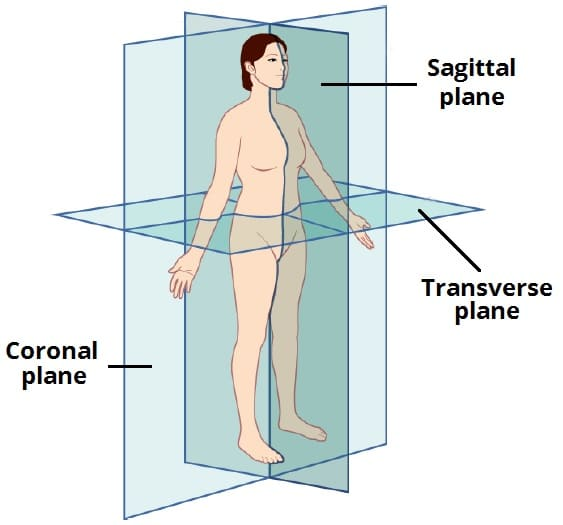

So of course we can display each modality through its different planes. For example, we will display the 3 planes of the T1 image:

In [ ]:
# Plot a RMI modality through all planes
slice_nb = 100

fig, axs2 = plt.subplots(1, 3, figsize=(10,10))
# Apply a 90° rotation with an automatic resizing, otherwise the display is less obvious to analyze
axs2[0].imshow(rotate(t1_data[slice_nb,:,:], 90, resize=True), cmap="gray")     #fisso primo indice->sagittale
axs2[0].set_title('T1 - Sagittal View')
axs2[1].imshow(rotate(t1_data[:,slice_nb,:], 90, resize=True), cmap="gray")     #fisso secondo indice->coronale
axs2[1].set_title('T1 - Coronal View')
axs2[2].imshow(t1_data[:,:,slice_nb], cmap="gray")                              #fisso terzo indice->assiale
axs2[2].set_title('T1 - Axial View')
for i in range(3): axs2[i].axis('off')
plt.show()

fig, axs3 = plt.subplots(1, 3, figsize=(10,10))
# Apply a 90° rotation with an automatic resizing, otherwise the display is less obvious to analyze
axs3[0].imshow(rotate(t2_data[slice_nb,:,:], 90, resize=True), cmap="gray")
axs3[0].set_title('T2 - Sagittal View')
axs3[1].imshow(rotate(t2_data[:,slice_nb,:], 90, resize=True), cmap="gray")
axs3[1].set_title('T2 - Coronal View')
axs3[2].imshow(t2_data[:,:,slice_nb], cmap="gray")
axs3[2].set_title('T2 - Axial View')
for i in range(3): axs3[i].axis('off')

fig, axs4 = plt.subplots(1, 3, figsize=(10,10))
# Apply a 90° rotation with an automatic resizing, otherwise the display is less obvious to analyze
axs4[0].imshow(rotate(t2_data[slice_nb,:,:], 90, resize=True), cmap="gray")
axs4[0].imshow(rotate(seg_data[slice_nb,:,:], 90, resize=True), cmap="turbo", alpha = 0.3)
axs4[0].set_title('T2 - Sagittal View')
axs4[1].imshow(rotate(t2_data[:,slice_nb,:], 90, resize=True), cmap="gray")
axs4[1].imshow(rotate(seg_data[:,slice_nb,:], 90, resize=True), cmap="turbo", alpha = 0.3)
axs4[1].set_title('T2 - Coronal View')
axs4[2].imshow(t2_data[:,:,slice_nb], cmap="gray")
axs4[2].imshow(seg_data[:,:, slice_nb], cmap="turbo", alpha = 0.3)
axs4[2].set_title('T2 - Axial View')
for i in range(3): axs4[i].axis('off')
plt.show()


Now that we know why we have three dimensions, let's try to understand why we chose to display a specific slice, by fixing the `slice_nb` to 100.

To do this, we will display all the slices:

In [ ]:
fig, ax1 = plt.subplots(1, 1, figsize = (15,15))
ax1.imshow(rotate(montage(t1_data[:,:,:]), 90, resize=True), cmap ='gray')                #montage->plotta determinate fette di un volume
ax1.imshow(rotate(montage(seg_data[:,:,:]), 90, resize=True), cmap ='turbo', alpha = 0.3)
ax1.axis('off')
# montage allows us to concatenate multiple images of the same size horizontally and vertically

#alcune fette sono tutte nere->buona norma toglierle
#non è detto che la segmentazione sia in tutte le aree del cervello


As you can see, two black parts are present on each side of our montage. These black parts correspond to the first and last slices of a plane, meaning that a part of the slices does not contain informations.


This is why we can exclude these slices in our analysis, in order to reduce the number of manipulated images. Indeed, you can see that **a (60:135) range will be much more interesting**:

In [ ]:
# Prova a visualizzare le immagini sagittali del cervello dalla slice 60 alla 135 e sovrapporre la segmentazione
fig, ax1 = plt.subplots(1, 1, figsize = (15,15))
ax1.imshow(rotate(montage(t1_data[60:135,:,:]), 90, resize=True), cmap ='gray')                #montage->plotta determinate fette di un volume
ax1.imshow(rotate(montage(seg_data[60:135,:,:]), 90, resize=True), cmap ='turbo', alpha = 0.3)
ax1.axis('off')


**To summarize data exploration:**

- We have for each sample / patient 4 different modalities (T1, T1CE, T2 & FLAIR), accompanied by a segmentation that indicates tumor areas.

- Each image is 3D, and can therefore be analyzed through 3 different planes that are composed of 2D slices.

- Many slices contain little or no information. We will only **keep the (60:135)** slices interval for this tutorial. Of course, you are free to customize the code to send less or more slices to your model, but the training time will be longer.

- A segmentation image contains 1 to 4 classes.

Now that we know more about our data, it is time to prepare the training of our model. **Our goal is to produce a segmentation model that segments the entire tumor area (all classes) from the T2 sequence**.

In [ ]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(some_seg_img[100,:,:] == 0, cmap='turbo')
plt.colorbar()
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(some_seg_img[100,:,:] == 1, cmap='turbo')
plt.colorbar()
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(some_seg_img[100,:,:] == 2, cmap='turbo')
plt.colorbar()
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(some_seg_img[100,:,:] == 4, cmap='turbo')
plt.colorbar()
plt.axis('off')


### Step 3 - Prepare data for Training

#### A - Split data into 3 sets
In the world of AI, the quality of a model is determined by its **ability to make accurate predictions on new, unseen data**. To achieve this, it is important to divide our data into three sets: **Training, Validation and Test**.

Reminder of their usefulness:
- **Training set** is used to train the model. During training, the model is exposed to the training data and adjusts its parameters to minimize the error between its predictions and the Ground truth (segmentations).

- **Validation set** is used to fine-tune the hyperparameters of our model, which are set before training and determine the behavior of our model. The aim is to compare different hyperparameters and select the best configuration for our model.

- **Test set** is used to evaluate the performance of our model after it has been trained, to see how well it performs on unseen data.

First, let's retrieve all samples that are present in the Training folder:

In [ ]:
samples = patient_ids[:100]
print("Number of patients:",len(samples))


Now, let's create our 3 different sets:

In [ ]:
# Split the dataset into train and validation sets
samples_train, samples_val = train_test_split(samples, test_size=0.2, random_state=42) #test_size=percentuale dei dati in 2 set, random_state=42 ho fissato i set con i run

# Split the train set into the real train set and in a test set
samples_train, samples_test = train_test_split(samples_train, test_size=0.15, random_state=42)

# Print data distribution (Train: 68%, Test: 12%, Val: 20%)
print(f"Train length: {len(samples_train)}")
print(f"Validation length: {len(samples_val)}")
print(f"Test length: {len(samples_test)}")


#### B - Create a DataGenerator

In order to train a neural network to segment objects in images, it is necessary to feed it with both the raw image data (X) and the ground truth segmentations (y). By combining these two types of data, the neural network can learn to recognize tumor patterns and make accurate predictions about the contents of a patient’s scan.

Unfortunately, our modalities images (X) and our segmentations (y) cannot be sent directly to the AI model. Indeed, loading all these 3D images would overload the memory of our environment and cause the system to crash. This will also lead to shape mismatch errors. We have to do some image preprocessing before, which will be done by using a **Data Generator**, where we will **perform any operation** that we think is necessary when loading the images.

    
More specifically, we will, for each sample:

- Retrieve the path of images

- Retrieve the path of the Ground truth (original segmentation)

- Load image & segmentation

- Create a X array that will contain all the selected slices (60-135) of the images.

- Create an y array that will contain all the selected slices of the segmentation.

- Select all classes and binarize.

We will work in the axial plane: Since the images are square in shape (240x240) in this plane. But since we will manipulate a range of slices, we will be able to visualize the predictions in the 3 planes, so it doesn't really have an impact.

You may wonder why we didn't resize the images in a (256, 256) shape, which also is a power of 2 and is closer to 240 than 64 is. This choice depends on several factors, such as the complexity of the model, the amount of training data, the computational resources available, and the desired balance between computational efficiency and information preservation.

Indeed, resizing images to (256, 256) may preserve more information than resizing to (64, 64), which could lead to better performance. However, this larger size also means that the model will have more parameters, which can increase the training time and memory requirements, which is the reason why we will choose the (64, 64) shape.

Obviously the size has been reduced so much because we have little time. Of course, you are free to try to train your model with (256, 256) or (128, 128)

In [ ]:
IMG_SIZE = 64
BATCH_SIZE = 1
VOLUME_START_AT = 60
VOLUME_SLICES = 75

def prepare_patient(patient, with_mask=True):
    volume = nib.load(str(volume_path(patient, "t2"))).get_fdata(dtype=np.float32)
    if volume.ndim != 3 or volume.shape[2] < VOLUME_START_AT + VOLUME_SLICES:
        raise ValueError(f"Invalid volume shape for {patient}: {volume.shape}")
    images = np.stack([cv2.resize(volume[:,:,j], (IMG_SIZE,IMG_SIZE))
                       for j in range(VOLUME_START_AT,VOLUME_START_AT+VOLUME_SLICES)])
    images = ((images-images.min()) / max(float(images.max()-images.min()),1e-8))[...,None].astype(np.float32)
    if not with_mask: return images
    mask = nib.load(str(volume_path(patient, "seg"))).get_fdata(dtype=np.float32)
    if mask.shape != volume.shape: raise ValueError(f"MRI/mask shape mismatch for {patient}")
    masks = np.stack([cv2.resize((mask[:,:,j]>0).astype(np.uint8), (IMG_SIZE,IMG_SIZE),
                                interpolation=cv2.INTER_NEAREST)
                      for j in range(VOLUME_START_AT,VOLUME_START_AT+VOLUME_SLICES)])
    return images, masks[...,None].astype(np.float32)

class DataGenerator(keras.utils.Sequence):
    def __init__(self, list_IDs, batch_size=BATCH_SIZE, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.list_IDs = list(list_IDs)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.on_epoch_end()
    def __len__(self):
        return int(np.ceil(len(self.list_IDs)/self.batch_size))
    def __getitem__(self,index):
        ids = self.indexes[index*self.batch_size:(index+1)*self.batch_size]
        pairs = [prepare_patient(self.list_IDs[i]) for i in ids]
        return np.concatenate([p[0] for p in pairs]), np.concatenate([p[1] for p in pairs])
    def on_epoch_end(self):
        self.indexes = np.arange(len(self.list_IDs))
        if self.shuffle: np.random.shuffle(self.indexes)

training_generator = DataGenerator(samples_train)
valid_generator = DataGenerator(samples_val, shuffle=False)
test_generator = DataGenerator(samples_test, shuffle=False)


In [ ]:
example=training_generator[0]
X_example,y_example=example
print(X_example.shape)
print(y_example.shape)

#img 64x64 ad 1 canale (livelli di grigio), 75 sono il numero di fette scelte, dipende dal batch: batch*75 è il primo valore



---
> * **DOMANDA**: Quale dimensione ti aspetti che abbia training_generator? Dipende dalla dimensione del batch?
---

**To summarize the preprocessing steps**:
- We use a data generator to be able to process and send our data to our neural network (since all our images cannot be stored in memory at once).
- For each epoch (single pass of the entire training dataset through a neural network), the model will receive the number of samples contained in our training dataset.
- For each sample, the model will have to analyze 75 slices, received in a (64, 64) shape, as an X array of a (batch_size*volume_size, img_size, img_size, 1) shape.

### Step 5 - Define the model

Now that we can iterate on our data, we can define our segmentation model.

#### A - U-Net

We will use the [U-Net architecture](https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/). This [CNN](https://en.wikipedia.org/wiki/Convolutional_neural_network) is designed for biomedical image segmentation, and is particularly well-suited for segmentation tasks where the regions of interest are small and have complex shapes (such as tumors in MRI scans).

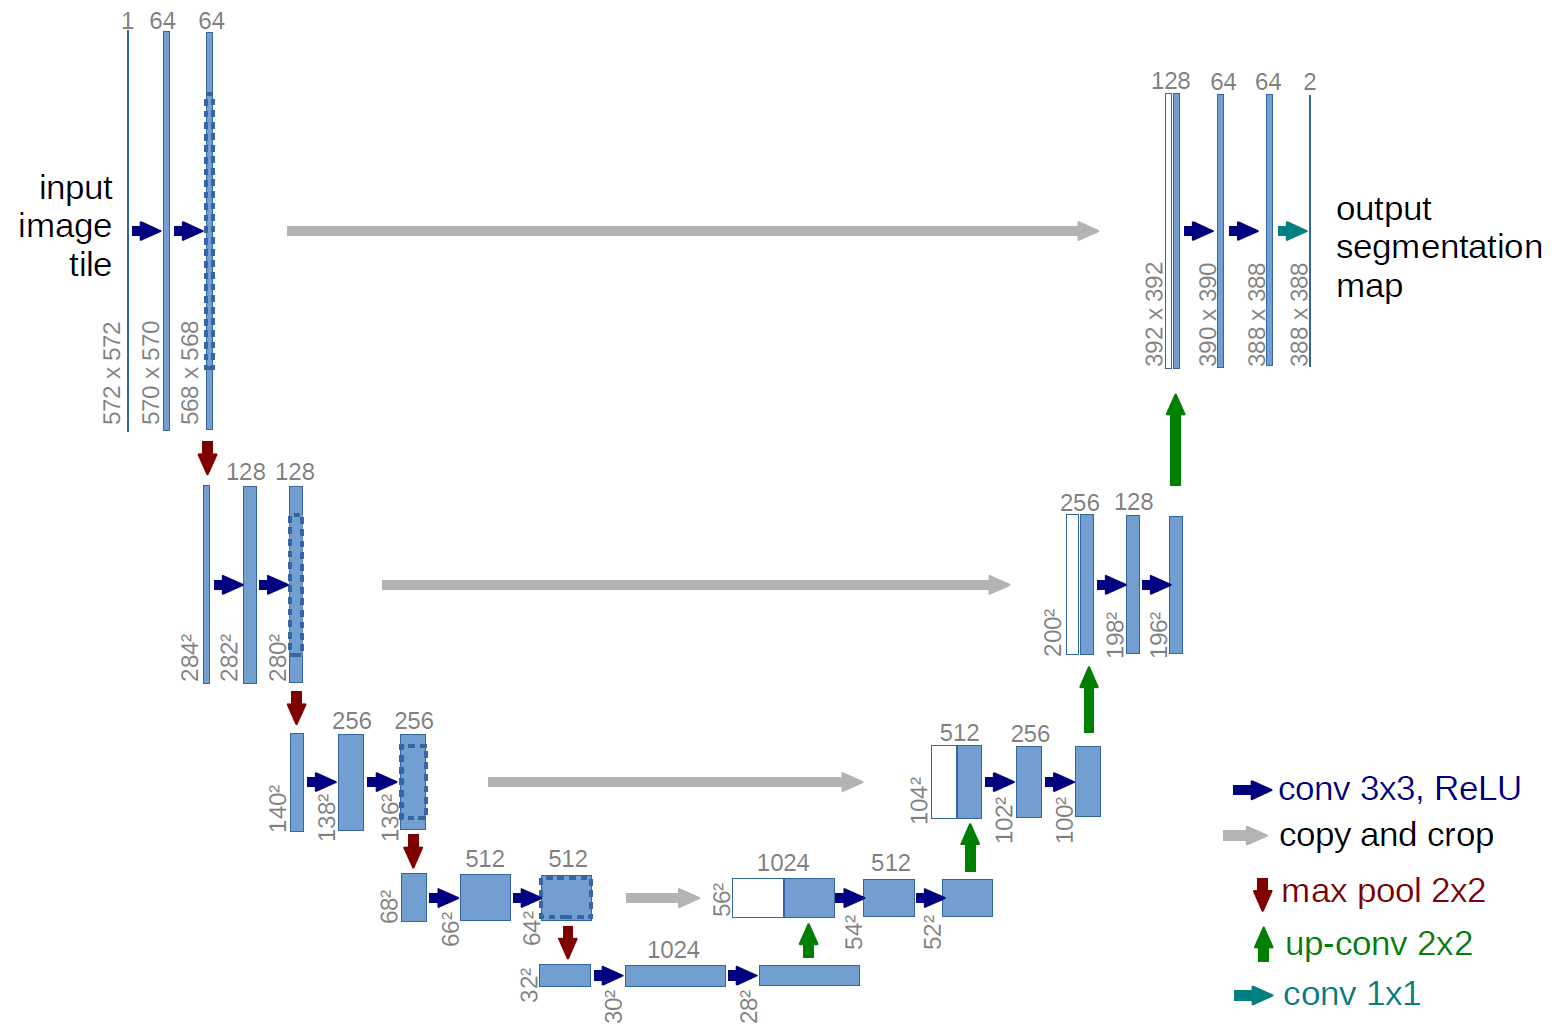

This neural network was first introduced in 2015 by *Olaf Ronneberger, Philipp Fischer, Thomas Brox* and reported in the paper *[U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597)*.

Since the BraTS2020 dataset consists of 3D images, where each consists of multiple 2D slices in three orthogonal planes, we have 2 possibilities. We can either use a 2D U-Net and a 3D U-Net.

In theory, a 3D U-Net is more adapted in our case. Indeed, a 3D U-Net can leverage the 3D spatial context of the images, which means it can reduce the risk of false positives and false negatives that can occur due to partial or incomplete information in individual 2D slices.
However, a 2D U-Net is faster and requires less memory than a 3D U-Net, which can be an advantage when working with large datasets or limited computational resources.
In practice, it is often useful to try both 2D and 3D U-Net architectures and compare their performance on the specific segmentation task.
For this reason, 2.5D U-Net approaches are often used. Basically, they consist of separately training 3 U-Nets on each view of the data (axial, sagittal and coronal) and then integrating the 3 predictions. In this way, it is possible not to lose the spatial coherence of the 3D datum but maintaining the computational advantages of 3D approaches.

In this tutorial, we will opt for a 2D neural network implementation:

In [ ]:
def build_unet(inputs, dropout):
    ker_init = 'he_normal'
    num_classes = 1
    conv1 = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(inputs)
    conv1 = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv1)

    pool = MaxPooling2D(pool_size=(2, 2))(conv1)
    conv = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool)
    conv = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv)

    pool1 = MaxPooling2D(pool_size=(2, 2))(conv)
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool1)
    conv2 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv2)

    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool2)
    conv3 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv3)

    pool4 = MaxPooling2D(pool_size=(2, 2))(conv3)
    conv5 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(pool4)
    conv5 = Conv2D(512, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv5)
    drop5 = Dropout(dropout)(conv5)

    up7 = Conv2D(256, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = 2)(drop5))
    merge7 = concatenate([conv3,up7], axis = 3)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge7)
    conv7 = Conv2D(256, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv7)

    up8 = Conv2D(128, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = 2)(conv7))   #espensione della dimensione
    merge8 = concatenate([conv2,up8], axis = 3)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge8)
    conv8 = Conv2D(128, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv8)

    up9 = Conv2D(64, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = 2)(conv8))
    merge9 = concatenate([conv,up9], axis = 3)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge9)
    conv9 = Conv2D(64, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv9)

    up = Conv2D(32, 2, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(UpSampling2D(size = 2)(conv9))
    merge = concatenate([conv1,up], axis = 3)
    conv = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(merge)
    conv = Conv2D(32, 3, activation = 'relu', padding = 'same', kernel_initializer = ker_init)(conv)

    conv10 = Conv2D(num_classes, 1, activation = 'sigmoid')(conv)               #binaria->sigmoide, multiclasse->softmax(garantisce che un pixel non venga classificato in più classi)
    # for multi-class segmentation you have to use softmax activation function in the last layer

    return Model(inputs = inputs, outputs = conv10)


#### B - Loss function

When training a CNN, it's important to choose a loss function that accurately reflects the performance of the network. Indeed, this function will allow to compare the predicted pixels to those of the ground truth for each patient. At each epoch, the goal is to update the weights of our model in a way that minimizes this loss function, and therefore improves the accuracy of its predictions.

A commonly used loss function for binary segmentation problems is **binary cross-entropy**, which measures the difference between the predicted probability distribution of each pixel and the real value of the encoded ground truth (in multi-class segmentation categorical cross-entropy is used). Note that segmentations models sometimes use the **dice loss** function as well.

#### C - Output activation function

To get this probability distribution for each pixel in binary segmentation, we apply a **sigmoid** activation function to the output layer of our neural network. In the case of multi-class segmentation softmax is used.

This means that during training, our CNN will adjust its weights to minimize our loss function, which compares predicted probabilities given by the sigmoid function with those of the ground truth segmentation.

#### D - Other metrics:

It is also important to monitor the model's performance using evaluation metrics.

We will of course use **accuracy**, which is a very popular measure. However, this metric can be misleading when working with imbalanced datasets like BraTS2020, where Background class is over represented. To address this issue, we will use other metrics such as the **the Dice coefficient, precision, sensitivity, and specificity**.

- **Accuracy**: Measures the overall proportion of correctly classified pixels, including both positive and negative pixels.

- **Sensitivity** (recall or true positive rate): Measures the proportion of positive ground truth pixels that were correctly predicted as positive.

- **Precision** (positive predictive value): Measures the proportion of predicted positive pixels that are actually positive.

- **Specificity** (true negative rate): Measures the proportion of negative ground truth pixels that were correctly predicted as negative.

In [ ]:
# Compute metric between the predicted segmentation and the ground truth
def dice_coef(y_true, y_pred, smooth=1.0):                                      #una delle migliori per SEGMENTAZIONE (Accuracy buona per classificazione, peggiore per segmentazione)
    class_num = 1
    for i in range(class_num):
        y_true_f = K.flatten(y_true[:,:,:,i])
        y_pred_f = K.flatten(y_pred[:,:,:,i])
        intersection = K.sum(y_true_f * y_pred_f)
        loss = ((2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth))
        if i == 0:
            total_loss = loss
        else:
            total_loss = total_loss + loss
    total_loss = total_loss / class_num
    return total_loss

def precision(y_true, y_pred):
        true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = true_positives / (predicted_positives + K.epsilon())
        return precision

def sensitivity(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    return true_positives / (possible_positives + K.epsilon())


def specificity(y_true, y_pred):
    true_negatives = K.sum(K.round(K.clip((1-y_true) * (1-y_pred), 0, 1)))
    possible_negatives = K.sum(K.round(K.clip(1-y_true, 0, 1)))
    return true_negatives / (possible_negatives + K.epsilon())



---
> * **DOMANDA**: Come si potrebbe implementare una loss function associata al dice score?*
---

In [ ]:
def dice_loss(y_true,y_pred):
    return 1.0 - dice_coef(y_true,y_pred)


#### E - Build the model

In [ ]:
# Define input data shape
input_layer = Input((IMG_SIZE, IMG_SIZE, 1))                                    #dim dell'input

# Build and compile the model
model = build_unet(input_layer, 0.2)                                            #costruzione U-Net
model.compile(loss="binary_crossentropy", optimizer=tensorflow.keras.optimizers.Adam(learning_rate=0.001), metrics = ['accuracy', dice_coef, precision, sensitivity, specificity] )
# for multi-class segmentation you have to set categorical_crossentropy (or a multi-class version of dice loss) as loss function


#### F - Set up callbacks

Callbacks are functions that can be executed during the training process.

We will use three callbacks:

- **EarlyStopping**: Stops training a neural network if a monitored metric stops improving, helping to avoid overfitting and save computational resources.

- **ReduceLROnPlateau**: This callback reduces the learning rate when a metric has stopped improving (validation loss here). The learning rate is reduced by a factor of 0.2, the patience is set to 2 epochs, and the minimum learning rate is set to 0.000001.

- **ModelCheckpoint**: Saves the best model weights (model that has obtained the lowest validation loss during the different epochs). Saving a model allows us to reuse it later or to share it, without having to retrain it from scratch. This will save us time and resources!

- **CSVLogger**: Add metrics to a CSV file, which is named *training.log* (parameter `append` is set to `False` so the file is overwritten if it already exists).

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_dice_coef",mode="max",patience=5,restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.2,patience=5),
    keras.callbacks.ModelCheckpoint(str(ARTIFACTS / "best.weights.h5"),monitor="val_dice_coef",mode="max",save_best_only=True,save_weights_only=True),
    keras.callbacks.CSVLogger(str(ARTIFACTS / "training.log"))
]


### Step 6 - Train & Save the model

We are now ready to train our deep neural network using the *.fit()* method in Keras. We will pass our 4 callbacks to the method so they can be executed during the training process, which will last 35 epochs.

In [ ]:
model.fit(training_generator,
          epochs=30,
          steps_per_epoch=len(training_generator),
          callbacks=callbacks,
          validation_data=valid_generator)


### Download trained weights for future inference

Thanks to our callbacks, weight files will be generated and added to your notebook's environment during the training.

If you don't want to lose your training, or if you want to reuse the model for future inference, I invite you to download your weights from the File Browser, on the left of the notebook interface.

Of course, it is legitimate to ask which files to download? Which ones contain the best weights? To answer these questions, we are going to analyze the scores obtained for each epoch.

### Metrics analysis

Now that the training has been completed, it's time to take a look at the CSVLogger callback, to get a better understanding of the training process and the performance of our model.

In [ ]:
# Read the CSVlogger file that contains all our metrics (accuracy, loss, dice_coef, ...) of our training
history = pd.read_csv(str(ARTIFACTS / 'training.log'), sep=',', engine='python')

# Plot training and validation metrics
fig, axs = plt.subplots(1, 3, figsize=(16, 8))

axs[0].plot(history['epoch'], history['accuracy'], 'b', label='Training Accuracy')
axs[0].plot(history['epoch'], history['val_accuracy'], 'r', label='Validation Accuracy')
axs[0].set_xlabel('Epoch')
axs[0].set_ylabel('Accuracy')
axs[0].legend()

axs[1].plot(history['epoch'], history['loss'], 'b', label='Training Loss')
axs[1].plot(history['epoch'], history['val_loss'], 'r', label='Validation Loss')
axs[1].set_xlabel('Epoch')
axs[1].set_ylabel('Loss')
axs[1].legend()

axs[2].plot(history['epoch'], history['dice_coef'], 'b', label='Training dice coef')
axs[2].plot(history['epoch'], history['val_dice_coef'], 'r', label='Validation dice coef')
axs[2].set_xlabel('Epoch')
axs[2].set_ylabel('Dice Coefficient')
axs[2].legend()

# Add space between subplots
plt.subplots_adjust(wspace=0.4)

plt.show()


Ideally, on the accuracy graph, you would see that both training accuracy and validation accuracy are increasing over epochs and reaching a plateau. This indicates that the model is learning from the data and generalizing well to new one.


### Step 7 - Predict tumor segmentations

Now that our model is trained, it's time to use it to predict the segmentations in our test dataset, using the best model's weights.

You can load a model with the following code:

In [ ]:
model.load_weights(str(ARTIFACTS / "best.weights.h5"))


Now, let's construct a function that allows us to predict the segmentation of a patient in the test dataset. I will choose a display in the axial plane, but we can totally choose another plane.

In [ ]:
def predict_segmentation(patient, bin_th=0.5):
    probabilities = model.predict(prepare_patient(patient,with_mask=False),verbose=0)
    return probabilities[...,0] > bin_th

def show_predicted_segmentations(samples_list, slice_to_plot, bin_th=0.5):
    patient = random.choice(samples_list)
    prediction = predict_segmentation(patient,bin_th)
    images, masks = prepare_patient(patient)
    fig, axes = plt.subplots(1,3,figsize=(12,4))
    for ax, image, title in zip(axes,[images[slice_to_plot,...,0],masks[slice_to_plot,...,0],prediction[slice_to_plot]],
                                ["T2","Whole-tumor ground truth","Prediction"]):
        ax.imshow(image,cmap="gray");ax.set_title(title);ax.axis("off")
    plt.suptitle(patient);plt.tight_layout();plt.show()


#### Plot Random predictions & Compare with Original (Ground truth)

In [ ]:
show_predicted_segmentations(samples_test, 60)


---
> **DOMANDA**: Come cambia la previsione cambiando le soglia di binarizzazione?
---

In [ ]:
thresholds = np.linspace(0.1,0.9,17)
intersection = np.zeros(len(thresholds)); predicted = np.zeros(len(thresholds)); actual = 0
for batch in range(len(valid_generator)):
    images, masks = valid_generator[batch]
    truth = masks > 0.5
    probabilities = model.predict(images,verbose=0)
    actual += truth.sum()
    for i, threshold in enumerate(thresholds):
        binary = probabilities > threshold
        intersection[i] += np.logical_and(binary,truth).sum()
        predicted[i] += binary.sum()
validation_dice = (2*intersection+1)/(predicted+actual+1)
best_threshold = float(thresholds[np.argmax(validation_dice)])
print("Validation-selected threshold:",best_threshold)
plt.plot(thresholds,validation_dice);plt.xlabel("Threshold");plt.ylabel("Pooled validation Dice");plt.show()
show_predicted_segmentations(samples_test,60,bin_th=best_threshold)


Here are some developments:

- **Neural Network**: Maybe change the model architecture.

- **Dataset**: Train the model on a larger dataset.

- **Modalities & slices**: Perhaps choose other or different modalities than the one we used. Select more slices or a different slices range for the model training.

- **Post-processing techniques**: Morphological operations like erosion / dilatation to refine the predicted segmentations.

### Step 8 - Evaluate the model
To finish, let's call the evaluate() function to evaluate the performance of our model on our test dataset.

In [ ]:
print("Soft Dice and default-threshold metrics:",model.evaluate(test_generator,return_dict=True))
intersection = predicted = actual = 0
for batch in range(len(test_generator)):
    images, masks = test_generator[batch]
    truth = masks > 0.5
    binary = model.predict(images,verbose=0) > best_threshold
    intersection += np.logical_and(binary,truth).sum()
    predicted += binary.sum(); actual += truth.sum()
print("Pooled test Dice at validation-selected threshold:",(2*intersection+1)/(predicted+actual+1))


Interpret results from the executed cells. Soft Dice differs from pooled binary Dice. This 2D educational segmentation model is not clinically validated.



I hope you have enjoyed this tutorial!



#### References
- [Article, U-Net Implementation for BraTS 2019 by Naomi Fridman](https://naomi-fridman.medium.com/multi-class-image-segmentation-a5cc671e647a)

- [Notebook, 3D MRI Brain tumor segmentation, by Rastislav](https://www.kaggle.com/code/rastislav/3d-mri-brain-tumor-segmentation-u-net)

- [The BraTS2020 Challenge](https://www.med.upenn.edu/cbica/brats2020/)

#### Papers
- [Information about the U-Net model, proposed by Ronneberger in 2015](https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/)

- [Advancing The Cancer Genome Atlas glioma MRI collections with expert segmentation labels and radiomic features, Nature Scientific Data, S. Bakas, H. Akbari, A. Sotiras, M. Bilello, M. Rozycki, J.S. Kirby, et al](https://pubmed.ncbi.nlm.nih.gov/28872634/)

- [Identifying the Best Machine Learning Algorithms for Brain Tumor Segmentation, Progression Assessment, and Overall Survival Prediction in the BRATS Challenge, S. Bakas, M. Reyes, A. Jakab, S. Bauer, M. Rempfler, A. Crimi, et al](https://arxiv.org/abs/1811.02629)

- [The Multimodal Brain Tumor Image Segmentation Benchmark (BRATS), IEEE Transactions on Medical Imaging, B. H. Menze, A. Jakab, S. Bauer, J. Kalpathy-Cramer, K. Farahani, J. Kirby, et al](https://pubmed.ncbi.nlm.nih.gov/25494501/)
